In [2]:
import pandas as pd
import numpy as np

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
# Step 3: Load the Heart Disease Dataset

df = pd.read_csv(r"C:\Users\ksshv\Desktop\cleaned_merged_heart_dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (1888, 14)


In [4]:
# Step 4: Display the First 5 Rows of the Dataset

print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [5]:
# Step 5: Check Dataset Information

print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1888 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1888 non-null   int64  
 1   sex       1888 non-null   int64  
 2   cp        1888 non-null   int64  
 3   trestbps  1888 non-null   int64  
 4   chol      1888 non-null   int64  
 5   fbs       1888 non-null   int64  
 6   restecg   1888 non-null   int64  
 7   thalachh  1888 non-null   int64  
 8   exang     1888 non-null   int64  
 9   oldpeak   1888 non-null   float64
 10  slope     1888 non-null   int64  
 11  ca        1888 non-null   int64  
 12  thal      1888 non-null   int64  
 13  target    1888 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 206.6 KB


In [6]:
# Step 6: Check for Missing Values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalachh    0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [7]:
# Step 7: Check for Duplicate Records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 1286


In [8]:
# Step 8: Remove Duplicate Records

df = df.drop_duplicates()

print("Duplicate records removed successfully")
print("New dataset shape:", df.shape)

Duplicate records removed successfully
New dataset shape: (602, 14)


In [9]:
# Step 9: Analyze the Target Variable

print("Target value counts:")
print(df["target"].value_counts())

print("\nTarget value percentages:")
print(df["target"].value_counts(normalize=True) * 100)

Target value counts:
target
0    310
1    292
Name: count, dtype: int64

Target value percentages:
target
0    51.495017
1    48.504983
Name: proportion, dtype: float64


In [10]:
# Step 10: Separate Features and Target Variable

X = df.drop("target", axis=1)
y = df["target"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (602, 13)
Target (y) shape: (602,)


In [12]:
# Step 11: Split Dataset into Training and Testing Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (481, 13)
Testing features shape: (121, 13)
Training target shape: (481,)
Testing target shape: (121,)


In [13]:
# Step 12: Scale the Features for SVM

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully")
print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully
Scaled training data shape: (481, 13)
Scaled testing data shape: (121, 13)


In [14]:
# Step 13: Train the SVM Model using RBF Kernel

from sklearn.svm import SVC

svm_model = SVC(kernel="rbf", random_state=42)

svm_model.fit(X_train_scaled, y_train)

print("SVM model trained successfully")

SVM model trained successfully


In [15]:
# Step 14: Make Predictions Using the SVM Model

y_pred = svm_model.predict(X_test_scaled)

print("Predictions completed successfully")
print("Number of predictions:", len(y_pred))
print("First 10 predictions:", y_pred[:10])

Predictions completed successfully
Number of predictions: 121
First 10 predictions: [0 0 0 1 0 0 1 0 0 0]


In [16]:
# Step 15: Calculate SVM Model Accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("SVM Model Accuracy:", accuracy)
print("SVM Model Accuracy (%):", accuracy * 100)

SVM Model Accuracy: 0.768595041322314
SVM Model Accuracy (%): 76.85950413223141


In [17]:
# Step 16: Generate the Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[48 14]
 [14 45]]


In [18]:
# Step 16A: Display the Complete Confusion Matrix

print(cm)

[[48 14]
 [14 45]]


In [19]:
# Step 17: Calculate Precision, Recall and F1-Score

from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Precision (%):", precision * 100)

print("Recall:", recall)
print("Recall (%):", recall * 100)

print("F1-Score:", f1)
print("F1-Score (%):", f1 * 100)

Precision: 0.7627118644067796
Precision (%): 76.27118644067797
Recall: 0.7627118644067796
Recall (%): 76.27118644067797
F1-Score: 0.7627118644067796
F1-Score (%): 76.27118644067797


In [20]:
# Step 18: Generate the Classification Report

from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        62
           1       0.76      0.76      0.76        59

    accuracy                           0.77       121
   macro avg       0.77      0.77      0.77       121
weighted avg       0.77      0.77      0.77       121



In [21]:
# Step 19: Train SVM Model using Linear Kernel

svm_linear = SVC(kernel="linear", random_state=42)

svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)

accuracy_linear = accuracy_score(y_test, y_pred_linear)

print("Linear Kernel Accuracy:", accuracy_linear)
print("Linear Kernel Accuracy (%):", accuracy_linear * 100)

Linear Kernel Accuracy: 0.7024793388429752
Linear Kernel Accuracy (%): 70.24793388429752


In [22]:
# Step 20: Train SVM Model using Polynomial Kernel

svm_poly = SVC(kernel="poly", random_state=42)

svm_poly.fit(X_train_scaled, y_train)

y_pred_poly = svm_poly.predict(X_test_scaled)

accuracy_poly = accuracy_score(y_test, y_pred_poly)

print("Polynomial Kernel Accuracy:", accuracy_poly)
print("Polynomial Kernel Accuracy (%):", accuracy_poly * 100)

Polynomial Kernel Accuracy: 0.6776859504132231
Polynomial Kernel Accuracy (%): 67.76859504132231


In [23]:
# Step 21: Train SVM Model using Sigmoid Kernel

svm_sigmoid = SVC(kernel="sigmoid", random_state=42)

svm_sigmoid.fit(X_train_scaled, y_train)

y_pred_sigmoid = svm_sigmoid.predict(X_test_scaled)

accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)

print("Sigmoid Kernel Accuracy:", accuracy_sigmoid)
print("Sigmoid Kernel Accuracy (%):", accuracy_sigmoid * 100)

Sigmoid Kernel Accuracy: 0.6528925619834711
Sigmoid Kernel Accuracy (%): 65.28925619834712


In [24]:
# Step 22: Compare Accuracy of All SVM Kernels

kernel_results = pd.DataFrame({
    "Kernel": ["Linear", "Polynomial", "RBF", "Sigmoid"],
    "Accuracy (%)": [
        accuracy_linear * 100,
        accuracy_poly * 100,
        accuracy * 100,
        accuracy_sigmoid * 100
    ]
})

print("SVM Kernel Comparison:")
print(kernel_results)

SVM Kernel Comparison:
       Kernel  Accuracy (%)
0      Linear     70.247934
1  Polynomial     67.768595
2         RBF     76.859504
3     Sigmoid     65.289256


Matplotlib is building the font cache; this may take a moment.


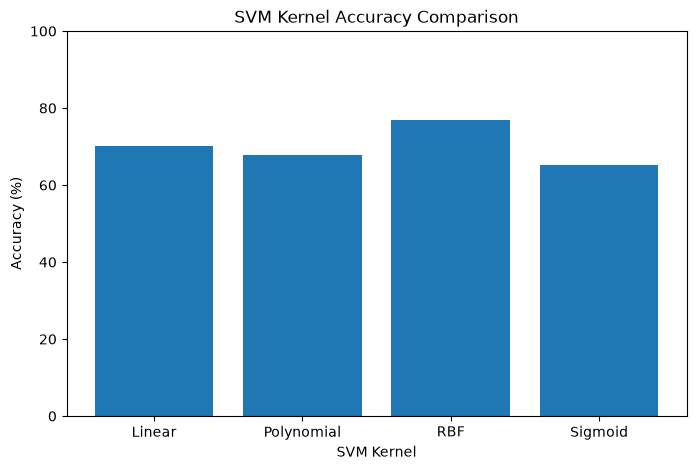

In [25]:
# Step 23: Visualize SVM Kernel Accuracy Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(kernel_results["Kernel"], kernel_results["Accuracy (%)"])

plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy (%)")
plt.title("SVM Kernel Accuracy Comparison")

plt.ylim(0, 100)
plt.show()

In [26]:
# Step 24: Compare Precision, Recall and F1-Score for All SVM Kernels

from sklearn.metrics import precision_score, recall_score, f1_score

kernel_predictions = {
    "Linear": y_pred_linear,
    "Polynomial": y_pred_poly,
    "RBF": y_pred,
    "Sigmoid": y_pred_sigmoid
}

evaluation_results = []

for kernel, predictions in kernel_predictions.items():
    evaluation_results.append({
        "Kernel": kernel,
        "Accuracy (%)": accuracy_score(y_test, predictions) * 100,
        "Precision (%)": precision_score(y_test, predictions) * 100,
        "Recall (%)": recall_score(y_test, predictions) * 100,
        "F1-Score (%)": f1_score(y_test, predictions) * 100
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("SVM Kernel Performance Comparison:")
print(evaluation_df.round(2))

SVM Kernel Performance Comparison:
       Kernel  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
0      Linear         70.25          68.25       72.88         70.49
1  Polynomial         67.77          75.00       50.85         60.61
2         RBF         76.86          76.27       76.27         76.27
3     Sigmoid         65.29          64.91       62.71         63.79


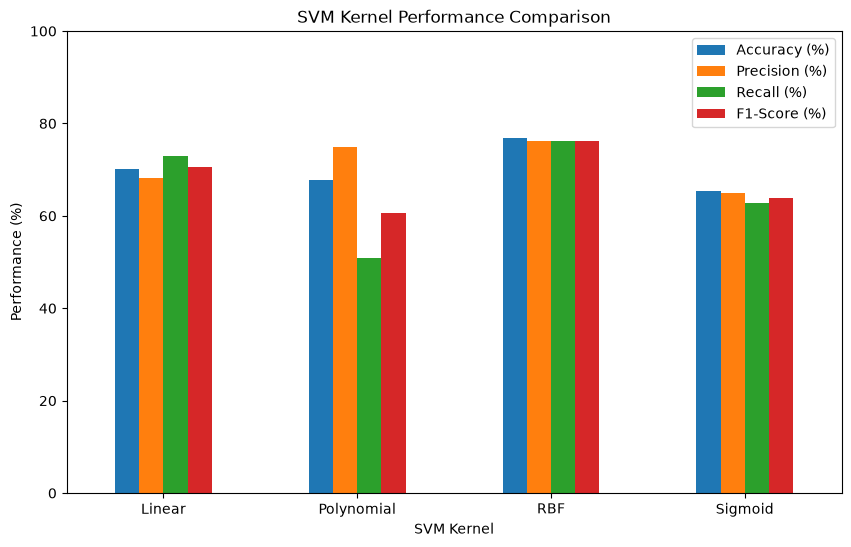

In [27]:
# Step 25: Visualize Complete SVM Kernel Performance

metrics = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]

evaluation_df.set_index("Kernel")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("SVM Kernel")
plt.ylabel("Performance (%)")
plt.title("SVM Kernel Performance Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.show()

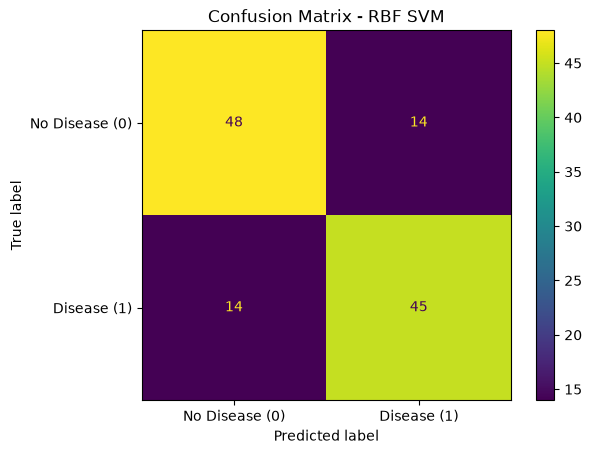

In [28]:
# Step 26: Visualize the Confusion Matrix for RBF SVM

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease (0)", "Disease (1)"]
)

disp.plot()

plt.title("Confusion Matrix - RBF SVM")
plt.show()

In [29]:
# Step 27: Test Different C Values for RBF SVM

C_values = [0.1, 1, 10, 100]

c_results = []

for c in C_values:
    model = SVC(kernel="rbf", C=c, random_state=42)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, predictions)

    c_results.append({
        "C": c,
        "Accuracy (%)": acc * 100
    })

c_results_df = pd.DataFrame(c_results)

print("RBF SVM Performance for Different C Values:")
print(c_results_df.round(2))

RBF SVM Performance for Different C Values:
       C  Accuracy (%)
0    0.1         69.42
1    1.0         76.86
2   10.0         77.69
3  100.0         76.86


In [30]:
# Step 28: Test Different Gamma Values for RBF SVM

gamma_values = ["scale", 0.01, 0.1, 1, 10]

gamma_results = []

for gamma in gamma_values:
    model = SVC(kernel="rbf", C=10, gamma=gamma, random_state=42)
    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, predictions)

    gamma_results.append({
        "Gamma": gamma,
        "Accuracy (%)": acc * 100
    })

gamma_results_df = pd.DataFrame(gamma_results)

print("RBF SVM Performance for Different Gamma Values:")
print(gamma_results_df.round(2))

RBF SVM Performance for Different Gamma Values:
   Gamma  Accuracy (%)
0  scale         77.69
1   0.01         71.07
2    0.1         79.34
3      1         65.29
4     10         52.89


In [31]:
# Step 29: Train the Tuned RBF SVM Model

final_svm = SVC(
    kernel="rbf",
    C=10,
    gamma=0.1,
    random_state=42
)

final_svm.fit(X_train_scaled, y_train)

final_predictions = final_svm.predict(X_test_scaled)

final_accuracy = accuracy_score(y_test, final_predictions)

print("Final Tuned RBF SVM trained successfully")
print("Final Model Accuracy:", final_accuracy)
print("Final Model Accuracy (%):", final_accuracy * 100)

Final Tuned RBF SVM trained successfully
Final Model Accuracy: 0.7933884297520661
Final Model Accuracy (%): 79.33884297520662


In [32]:
# Step 30: Evaluate the Final Tuned RBF SVM Model

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

final_cm = confusion_matrix(y_test, final_predictions)

final_precision = precision_score(y_test, final_predictions)
final_recall = recall_score(y_test, final_predictions)
final_f1 = f1_score(y_test, final_predictions)

print("Final Tuned RBF SVM Results")
print("--------------------------------")
print("Accuracy  :", final_accuracy * 100)
print("Precision :", final_precision * 100)
print("Recall    :", final_recall * 100)
print("F1-Score  :", final_f1 * 100)

print("\nFinal Confusion Matrix:")
print(final_cm)

Final Tuned RBF SVM Results
--------------------------------
Accuracy  : 79.33884297520662
Precision : 77.41935483870968
Recall    : 81.35593220338984
F1-Score  : 79.33884297520662

Final Confusion Matrix:
[[48 14]
 [11 48]]


In [33]:
# Step 31: Generate Classification Report for the Final Tuned RBF SVM

from sklearn.metrics import classification_report

print("Final Tuned RBF SVM Classification Report:")
print(classification_report(y_test, final_predictions))

Final Tuned RBF SVM Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.77      0.79        62
           1       0.77      0.81      0.79        59

    accuracy                           0.79       121
   macro avg       0.79      0.79      0.79       121
weighted avg       0.79      0.79      0.79       121



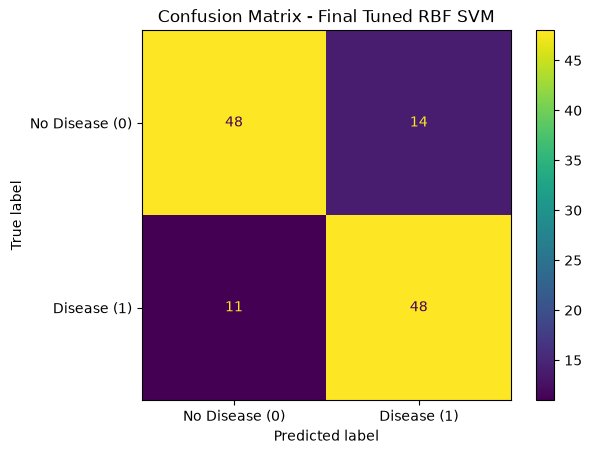

In [34]:
# Step 32: Visualize the Confusion Matrix of the Final Tuned RBF SVM

from sklearn.metrics import ConfusionMatrixDisplay

final_disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["No Disease (0)", "Disease (1)"]
)

final_disp.plot()

plt.title("Confusion Matrix - Final Tuned RBF SVM")
plt.show()

In [35]:
# Step 33: Create Final Model Results Table

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score (%)": [
        final_accuracy * 100,
        final_precision * 100,
        final_recall * 100,
        final_f1 * 100
    ]
})

print("Final Tuned RBF SVM Results:")
print(final_results.round(2))

Final Tuned RBF SVM Results:
      Metric  Score (%)
0   Accuracy      79.34
1  Precision      77.42
2     Recall      81.36
3   F1-Score      79.34


In [1]:
print("ML Project Started")

ML Project Started
